<a href="https://colab.research.google.com/github/nathalia2000-web/Entrega-final---Playground-Final-Project/blob/main/DS_II_%2BPu%C3%B1al.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final – Visualización y Modelado Predictivo en Fórmula 1

Alumno/a:Natalia Puñal  
Comisión: Data Science  
Dataset: FIA Formula 1 1950–2020 Data  
Fuente: Kaggle  

---
# Predicción de puntos en Fórmula 1 mediante Machine Learning

## Objetivo del proyecto

El objetivo de este proyecto es analizar resultados históricos de Fórmula 1 y construir un modelo de regresión capaz de estimar los puntos obtenidos por un piloto en una carrera.

Para realizar la predicción se utilizan variables disponibles antes de la carrera, como el año, la posición de clasificación, el equipo, el piloto y la sede del evento.

También se busca identificar patrones de rendimiento y evaluar si el modelo mejora una predicción base basada únicamente en el promedio histórico de puntos.




Abstract

Este proyecto analiza información histórica de la Fórmula 1 correspondiente al período 1950–2020. El dataset reúne registros de resultados de carreras, clasificaciones de pilotos y clasificaciones de constructores, lo que permite estudiar la evolución competitiva de una de las categorías más relevantes del automovilismo mundial. El análisis se concentra principalmente en los resultados de carrera, debido a que este archivo contiene variables vinculadas con la posición de partida, la posición final, los puntos obtenidos, los pilotos, los constructores y las temporadas.

El objetivo exploratorio consiste en identificar cómo se relacionan la posición de largada, el constructor y el período histórico con los puntos obtenidos por los pilotos. Se busca responder si comenzar una carrera en una posición más adelantada aumenta la posibilidad de sumar puntos, qué equipos concentraron mayor rendimiento en distintos períodos y cómo evolucionó la distribución de puntos a lo largo de las temporadas. Para ello se aplican técnicas de análisis exploratorio de datos, resúmenes estadísticos y visualizaciones univariadas, bivariadas y multivariadas.

También se realiza una evaluación de la calidad de los datos mediante la identificación de valores faltantes, duplicados, tipos de variables y posibles registros atípicos. Esta etapa es especialmente relevante porque algunos campos históricos de Fórmula 1 pueden estar incompletos, ya sea por cambios en los sistemas de registro o por diferencias reglamentarias entre épocas.

En la segunda parte se plantea un problema de regresión: predecir la cantidad de puntos obtenidos por un piloto en una carrera. Como variables predictoras se consideran la posición de largada, el año, el piloto y el constructor. Se excluyen deliberadamente variables conocidas luego de finalizada la carrera, tales como la posición final, las vueltas completadas y el estado de llegada, con el objetivo de evitar fuga de información. Se utiliza selección de variables mediante información mutua y un modelo de Árbol de Decisión para Regresión. Finalmente, se evalúa el desempeño del modelo tanto sobre entrenamiento como sobre prueba utilizando MAE, RMSE y coeficiente de determinación R^2.

El proyecto permite integrar análisis visual, tratamiento de datos, selección de atributos y modelado predictivo, manteniendo buenas prácticas de validación y evitando data leakage.


# Pregunta problema e hipótesis

## Pregunta problema

¿En qué medida la posición obtenida en clasificación, el equipo, el piloto, el circuito y el año permiten explicar o predecir los puntos obtenidos por un piloto en una carrera de Fórmula 1?

## Preguntas de interés

1. ¿Cómo se distribuyen los puntos obtenidos por los pilotos en las carreras de Fórmula 1?
2. ¿Existe una relación entre la posición de clasificación y los puntos obtenidos?
3. ¿Qué equipos acumularon mayor cantidad de puntos a lo largo de la historia?
4. ¿Cómo evolucionaron los puntos obtenidos por los principales equipos en diferentes temporadas?
5. ¿Qué variables previas a una carrera son más útiles para predecir los puntos obtenidos?

## Hipótesis

- **H1:** Los pilotos que clasifican en posiciones más adelantadas obtienen, en promedio, más puntos.
- **H2:** Algunos equipos concentran una proporción importante de los puntos debido a períodos de superioridad competitiva.
- **H3:** La relación entre posición de clasificación y puntos obtenidos puede variar entre períodos históricos.
- **H4:** La posición de clasificación será una variable importante para predecir los puntos obtenidos.


Librerias


Importación de librerías — Celda de código

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aadiltajani/fia-f1-19502019-data")

print("Path to dataset files:", path)

100%|██████████| 1.35M/1.35M [00:00<00:00, 110MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/aadiltajani/fia-f1-19502019-data/versions/28


In [ ]:
from pathlib import Path

DATA_PATH = Path(path)

archivos_csv = list(DATA_PATH.rglob("*.csv"))

print("Archivos CSV encontrados:\n")

for archivo in archivos_csv:
    print("-", archivo.name)


Archivos CSV encontrados:

- 70_Anniversary Q2_LapbyLap.csv
- 70_Anniversary Q3_LapbyLap.csv
- fastest_laps_1950-2020.csv
- race_results_1950-2020.csv
- qualifying_times_2006-2020.csv
- 70_Anniversary_Race_LapbyLap .csv
- race_wins_1950-2020.csv
- Monaz2020_Race_LapbyLap.csv
- Spain2020_Q2_LapbyLap.csv
- Spain2020_Q1_LapbyLap.csv
- Spain2020_Q3_LapbyLap.csv
- 70_Anniversary Q1_LapbyLap.csv
- qualifying_times_1950-2005.csv
- Spain2020_Race_LapbyLap.csv
- fastest_laps_all_drivers_all_race_1950-2020.csv
- drivers_championship_1950-2020.csv
- constructors_championship_1958-2020.csv


In [ ]:
for archivo in archivos_csv:
    print("\n" + "=" * 80)
    print("Archivo:", archivo.name)

    prueba = pd.read_csv(archivo, encoding="latin1")

    print("Dimensiones:", prueba.shape)
    print("Columnas:")
    print(prueba.columns.tolist())

    display(prueba.head(3))



Archivo: 70_Anniversary Q2_LapbyLap.csv
Dimensiones: (3964, 5)
Columnas:
['index', 'pos', 'driver', 'gap', 'time_remaining']


,index,pos,driver,gap,time_remaining
0,1,1,Valtteri,- -,00:12:49
1,1,2,Lewis,- -,00:12:49
2,1,3,Alexander,- -,00:12:49



Archivo: 70_Anniversary Q3_LapbyLap.csv
Dimensiones: (5220, 5)
Columnas:
['index', 'pos', 'driver', 'gap', 'time_remaining']


,index,pos,driver,gap,time_remaining
0,1,1,Valtteri,- -,00:09:09
1,1,2,Lewis,- -,00:09:09
2,1,3,Pierre,- -,00:09:09



Archivo: fastest_laps_1950-2020.csv
Dimensiones: (1035, 7)
Columnas:
['Unnamed: 0', 'Year', 'Venue', 'Name', 'Driver Tag', 'Team', 'Lap Time']


,Unnamed: 0,Year,Venue,Name,Driver Tag,Team,Lap Time
0,0,1950,Great Britain,Nino Farina,FAR,Alfa Romeo,1:50.600
1,1,1950,Monaco,Juan Manuel Fangio,FAN,Alfa Romeo,1:51.000
2,2,1950,Indianapolis 500,Johnnie Parsons,PAR,Kurtis Kraft Offenhauser,NaN


... (24 outputs left out)


Archivo: drivers_championship_1950-2020.csv
Dimensiones: (1575, 8)
Columnas:
['Unnamed: 0', 'Year', 'Position', 'Name', 'Driver Tag', 'Nationality', 'Team', 'Points']


,Unnamed: 0,Year,Position,Name,Driver Tag,Nationality,Team,Points
0,0,1950,1,Nino Farina,FAR,ITA,Alfa Romeo,30.0
1,1,1950,2,Juan Manuel Fangio,FAN,ARG,Alfa Romeo,27.0
2,2,1950,3,Luigi Fagioli,FAG,ITA,Alfa Romeo,24.0



Archivo: constructors_championship_1958-2020.csv
Dimensiones: (655, 5)
Columnas:
['Unnamed: 0', 'Year', 'Position', 'Team', 'Points']


,Unnamed: 0,Year,Position,Team,Points
0,0,1958,1,Vanwall,48
1,1,1958,2,Ferrari,40
2,2,1958,3,Cooper Climax,31


Importacion de datos


In [ ]:
import pandas as pd
from pathlib import Path

race_file = next(
    archivo for archivo in archivos_csv
    if archivo.name == "race_results_1950-2020.csv"
)

print("Archivo seleccionado:", race_file)

df_races = pd.read_csv(race_file)

print("Dimensiones del dataset:", df_races.shape)

display(df_races.head())


Archivo seleccionado: /root/.cache/kagglehub/datasets/aadiltajani/fia-f1-19502019-data/versions/28/race_results_1950-2020.csv
Dimensiones del dataset: (23155, 11)


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Laps,Time,Points
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0
3,3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0
4,4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0


## Dimensiones y estructura del dataset principal

El dataset principal contiene registros históricos de carreras de Fórmula 1. Cada fila representa el resultado de un piloto en una carrera determinada.

La cantidad de filas es relevante porque permite disponer de una muestra amplia para realizar análisis descriptivos y separar datos de entrenamiento y prueba durante la etapa de modelado.


In [ ]:
df_races.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23155 entries, 0 to 23154
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  23155 non-null  int64  
 1   Year        23155 non-null  int64  
 2   Position    23155 non-null  object 
 3   Driver No.  23155 non-null  int64  
 4   Venue       23155 non-null  object 
 5   Name        23155 non-null  object 
 6   NameTag     23155 non-null  object 
 7   Team        23129 non-null  object 
 8   Laps        22931 non-null  float64
 9   Time        23147 non-null  object 
 10  Points      23155 non-null  float64
dtypes: float64(2), int64(3), object(6)
memory usage: 1.9+ MB


In [ ]:
print(df_races.columns.tolist())


['Unnamed: 0', 'Year', 'Position', 'Driver No.', 'Venue', 'Name', 'NameTag', 'Team', 'Laps', 'Time', 'Points']


## Limpieza inicial del dataset de resultados

Se normalizarán los nombres de las columnas para facilitar la lectura y el uso posterior en gráficos y modelos. También se eliminará una columna de índice que no aporta información analítica.


In [ ]:
df = df_races.copy()

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(df.columns.tolist())

display(df.head())


['unnamed:_0', 'year', 'position', 'driver_no.', 'venue', 'name', 'nametag', 'team', 'laps', 'time', 'points']


,unnamed:_0,year,position,driver_no.,venue,name,nametag,team,laps,time,points
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0
3,3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0
4,4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0


In [ ]:
[
    'unnamed:_0',
    'year',
    'position',
    'driver_no.',
    'venue',
    'name',
    'nametag',
    'team',
    'laps',
    'time',
    'points'
]


['unnamed:_0',
 'year',
 'position',
 'driver_no.',
 'venue',
 'name',
 'nametag',
 'team',
 'laps',
 'time',
 'points']

In [ ]:
df = df.drop(columns=["unnamed:_0"], errors="ignore")

display(df.head())


,year,position,driver_no.,venue,name,nametag,team,laps,time,points
0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0
3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0
4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0


In [ ]:
df = df.rename(columns={
    "year": "year",
    "position": "final_position",
    "driver_no.": "driver_number",
    "venue": "venue",
    "name": "driver",
    "nametag": "driver_tag",
    "team": "team",
    "laps": "laps",
    "time": "race_time",
    "points": "points"
})

print(df.columns.tolist())


['year', 'final_position', 'driver_number', 'venue', 'driver', 'driver_tag', 'team', 'laps', 'race_time', 'points']


In [ ]:
missing = pd.DataFrame({
    "cantidad_faltantes": df.isna().sum(),
    "porcentaje_faltantes": (df.isna().sum() / len(df) * 100).round(2)
})

missing = missing.sort_values(
    by="cantidad_faltantes",
    ascending=False
)

missing


,cantidad_faltantes,porcentaje_faltantes
laps,224,0.97
team,26,0.11
race_time,8,0.03
year,0,0.00
final_position,0,0.00
driver_number,0,0.00
driver_tag,0,0.00
driver,0,0.00
venue,0,0.00
points,0,0.00


In [ ]:
duplicados = df.duplicated().sum()

print("Cantidad de filas duplicadas:", duplicados)
print("Porcentaje de duplicados:", round(duplicados / len(df) * 100, 2), "%")


Cantidad de filas duplicadas: 0
Porcentaje de duplicados: 0.0 %


In [ ]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["final_position"] = pd.to_numeric(df["final_position"], errors="coerce")
df["driver_number"] = pd.to_numeric(df["driver_number"], errors="coerce")
df["laps"] = pd.to_numeric(df["laps"], errors="coerce")
df["points"] = pd.to_numeric(df["points"], errors="coerce")

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23155 entries, 0 to 23154
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            23155 non-null  int64  
 1   final_position  14438 non-null  float64
 2   driver_number   23155 non-null  int64  
 3   venue           23155 non-null  object 
 4   driver          23155 non-null  object 
 5   driver_tag      23155 non-null  object 
 6   team            23129 non-null  object 
 7   laps            22931 non-null  float64
 8   race_time       23147 non-null  object 
 9   points          23155 non-null  float64
dtypes: float64(3), int64(2), object(5)
memory usage: 1.8+ MB


In [ ]:
df[["year", "final_position", "driver_number", "laps", "points"]].describe().T


,count,mean,std,min,25%,50%,75%,max
year,23155.0,1989.708616,19.097436,1950.0,1976.0,1991.0,2006.0,2020.0
final_position,14438.0,8.091356,5.137336,1.0,4.0,7.0,11.0,33.0
driver_number,23155.0,16.937033,14.559778,0.0,7.0,15.0,23.0,136.0
laps,22931.0,49.029829,27.742497,0.0,29.0,53.0,67.0,200.0
points,23155.0,1.903010,4.096215,0.0,0.0,0.0,2.0,50.0


## Incorporación de datos de clasificación

Los resultados de carrera no contienen directamente la posición de largada o clasificación. Por ese motivo, se incorporarán los archivos de clasificación de los períodos 1950–2005 y 2006–2020.

La posición de clasificación es una variable relevante porque se conoce antes del inicio de la carrera. Por lo tanto, puede utilizarse posteriormente para predecir puntos sin introducir fuga de información.


In [ ]:
qualifying_old_file = next(
    archivo for archivo in archivos_csv
    if archivo.name == "qualifying_times_1950-2005.csv"
)

df_qualifying_old = pd.read_csv(qualifying_old_file)

print("Dimensiones clasificación 1950–2005:", df_qualifying_old.shape)

display(df_qualifying_old.head())


Dimensiones clasificación 1950–2005: (9949, 10)


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Lap Time,Laps
0,0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,1:50.800,NaN
1,1,1950,1,34,monaco,Juan Manuel Fangio,FAN,Alfa Romeo,1:50.200,NaN
2,2,1950,1,98,indianapolis-500,Walt Faulkner,FAU,Kurtis Kraft Offenhauser,1:06.992,NaN
3,3,1950,1,14,switzerland,Juan Manuel Fangio,FAN,Alfa Romeo,2:42.100,NaN
4,4,1950,1,8,belgium,Nino Farina,FAR,Alfa Romeo,4:37.000,NaN


In [ ]:
qualifying_new_file = next(
    archivo for archivo in archivos_csv
    if archivo.name == "qualifying_times_2006-2020.csv"
)

df_qualifying_new = pd.read_csv(qualifying_new_file)

print("Dimensiones clasificación 2006–2020:", df_qualifying_new.shape)

display(df_qualifying_new.head())


Dimensiones clasificación 2006–2020: (6089, 12)


,Unnamed: 0,Year,Position,Driver No.,Venue,Name,NameTag,Team,Q1,Q2,Q3,Laps
0,0,2006,1,5,bahrain,Michael Schumacher,MSC,Ferrari,1:33.310,1:32.025,1:31.431,20
1,1,2006,2,6,bahrain,Felipe Massa,MAS,Ferrari,1:33.579,1:32.014,1:31.478,20
2,2,2006,3,12,bahrain,Jenson Button,BUT,Honda,1:32.603,1:32.025,1:31.549,23
3,3,2006,4,1,bahrain,Fernando Alonso,ALO,Renault,1:32.433,1:31.215,1:31.702,20
4,4,2006,5,4,bahrain,Juan Pablo Montoya,MOY,McLaren Mercedes,1:33.233,1:31.487,1:32.164,20


In [ ]:
# Conservar solamente las variables necesarias de cada período.
df_qualifying_old = df_qualifying_old[
    ["Year", "Venue", "NameTag", "Position", "Team"]
].copy()

df_qualifying_new = df_qualifying_new[
    ["Year", "Venue", "NameTag", "Position", "Team"]
].copy()

# Unificar ambas tablas.
df_qualifying = pd.concat(
    [df_qualifying_old, df_qualifying_new],
    ignore_index=True
)

# Normalizar nombres de columnas.
df_qualifying.columns = (
    df_qualifying.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# Renombrar para diferenciar posición de clasificación y posición final.
df_qualifying = df_qualifying.rename(columns={
    "nametag": "driver_tag",
    "position": "qualifying_position",
    "team": "qualifying_team"
})

# Convertir a numéricas las variables que deben ser numéricas.
df_qualifying["year"] = pd.to_numeric(
    df_qualifying["year"],
    errors="coerce"
)

df_qualifying["qualifying_position"] = pd.to_numeric(
    df_qualifying["qualifying_position"],
    errors="coerce"
)

print("Dimensiones del dataset consolidado de clasificación:")
print(df_qualifying.shape)

display(df_qualifying.head())


Dimensiones del dataset consolidado de clasificación:
(16038, 5)


,year,venue,driver_tag,qualifying_position,qualifying_team
0,1950,great-britain,FAR,1.0,Alfa Romeo
1,1950,monaco,FAN,1.0,Alfa Romeo
2,1950,indianapolis-500,FAU,1.0,Kurtis Kraft Offenhauser
3,1950,switzerland,FAN,1.0,Alfa Romeo
4,1950,belgium,FAR,1.0,Alfa Romeo


In [ ]:
duplicados_qualifying = df_qualifying.duplicated(
    subset=["year", "venue", "driver_tag"]
).sum()

print(
    "Duplicados según año, circuito y piloto:",
    duplicados_qualifying
)


Duplicados según año, circuito y piloto: 270


In [ ]:
df_qualifying = df_qualifying.drop_duplicates(
    subset=["year", "venue", "driver_tag"],
    keep="first"
)


In [ ]:
# Crear una copia del archivo de resultados de carrera
df_races_clean = df_races.copy()

# Normalizar los nombres de las columnas
df_races_clean.columns = (
    df_races_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# Eliminar la columna de índice innecesaria
df_races_clean = df_races_clean.drop(
    columns=["unnamed:_0"],
    errors="ignore"
)

# Renombrar columnas para que sean más descriptivas
df_races_clean = df_races_clean.rename(columns={
    "position": "final_position",
    "driver_no.": "driver_number",
    "name": "driver",
    "nametag": "driver_tag",
    "team": "team",
    "time": "race_time"
})

print("Dimensiones de resultados limpios:", df_races_clean.shape)
print("Columnas:")
print(df_races_clean.columns.tolist())

display(df_races_clean.head())


Dimensiones de resultados limpios: (23155, 10)
Columnas:
['year', 'final_position', 'driver_number', 'venue', 'driver', 'driver_tag', 'team', 'laps', 'race_time', 'points']


,year,final_position,driver_number,venue,driver,driver_tag,team,laps,race_time,points
0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0
1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0
2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0
3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0
4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0


In [ ]:
print("Dimensiones de clasificación:", df_qualifying.shape)
print(df_qualifying.columns.tolist())

display(df_qualifying.head())


Dimensiones de clasificación: (15768, 5)
['year', 'venue', 'driver_tag', 'qualifying_position', 'qualifying_team']


,year,venue,driver_tag,qualifying_position,qualifying_team
0,1950,great-britain,FAR,1.0,Alfa Romeo
1,1950,monaco,FAN,1.0,Alfa Romeo
2,1950,indianapolis-500,FAU,1.0,Kurtis Kraft Offenhauser
3,1950,switzerland,FAN,1.0,Alfa Romeo
4,1950,belgium,FAR,1.0,Alfa Romeo


## Integración de resultados y clasificación

La unión se realizará utilizando tres variables compartidas:

- Año.
- Circuito o sede de la carrera.
- Identificador abreviado del piloto.

Se utilizará una unión de tipo `left join`. Esto permite conservar todos los resultados de carrera, aun cuando no se encuentre información de clasificación para alguna observación histórica.


In [ ]:
df = df_races_clean.merge(
    df_qualifying[
        ["year", "venue", "driver_tag", "qualifying_position"]
    ],
    on=["year", "venue", "driver_tag"],
    how="left"
)

print("Dimensiones del dataset integrado:")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

display(df.head())


Dimensiones del dataset integrado:
Filas: 23,155
Columnas: 11


,year,final_position,driver_number,venue,driver,driver_tag,team,laps,race_time,points,qualifying_position
0,1950,1,2,great-britain,Nino Farina,FAR,Alfa Romeo,70.0,2:13:23.600,9.0,1.0
1,1950,2,3,great-britain,Luigi Fagioli,FAG,Alfa Romeo,70.0,+2.600s,6.0,NaN
2,1950,3,4,great-britain,Reg Parnell,PAR,Alfa Romeo,70.0,+52.000s,4.0,NaN
3,1950,4,14,great-britain,Yves Giraud Cabantous,CAB,Talbot-Lago,68.0,+2 laps,3.0,NaN
4,1950,5,15,great-britain,Louis Rosier,ROS,Talbot-Lago,68.0,+2 laps,2.0,NaN


In [ ]:
print("Filas antes de unir:", df_races_clean.shape[0])
print("Filas después de unir:", df.shape[0])

if df.shape[0] == df_races_clean.shape[0]:
    print("✅ Correcto: la unión no agregó registros.")
else:
    print("⚠️ Atención: la unión agregó filas. Hay que revisar duplicados en clasificación.")


Filas antes de unir: 23155
Filas después de unir: 23155
✅ Correcto: la unión no agregó registros.


## Validación de la integración de fuentes

La unión entre los resultados de carrera y los datos de clasificación se realizó correctamente. El dataset de resultados contenía 23.155 registros antes de la integración y mantuvo exactamente la misma cantidad después del proceso.

Esto confirma que no se generaron filas adicionales durante el merge. Cada fila continúa representando la participación de un piloto en una carrera, mientras que se incorporó la variable `qualifying_position`, correspondiente a la posición obtenida en clasificación.

La conservación de la cantidad de registros es importante porque evita duplicar observaciones, lo cual podría afectar los resúmenes numéricos, las visualizaciones y el entrenamiento del modelo predictivo.


# Calidad de datos y preparación para el análisis

En esta sección se revisan valores faltantes, registros duplicados, tipos de variables y estadísticas descriptivas. Estas verificaciones permiten conocer la calidad del dataset antes de generar visualizaciones y entrenar un modelo.


In [ ]:
missing = pd.DataFrame({
    "cantidad_faltantes": df.isna().sum(),
    "porcentaje_faltantes": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing = missing.sort_values(
    by="cantidad_faltantes",
    ascending=False
)

missing


,cantidad_faltantes,porcentaje_faltantes
qualifying_position,8110,35.02
laps,224,0.97
team,26,0.11
race_time,8,0.03
driver_number,0,0.00
year,0,0.00
final_position,0,0.00
driver_tag,0,0.00
driver,0,0.00
venue,0,0.00


## Interpretación de valores faltantes

La variable con mayor proporción de valores faltantes es `qualifying_position`, con 8.110 registros faltantes, equivalentes al 35,02% del dataset integrado. Esto puede estar vinculado a la falta de información histórica de clasificación en algunas carreras, a pilotos que no participaron de la clasificación, a cambios en los formatos de competición o a diferencias en la forma de registrar los datos entre los archivos utilizados.

Debido a que la posición de clasificación es una variable relevante y se conoce antes de la carrera, se conservará para el análisis y para el modelo predictivo. En las visualizaciones que incluyan esta variable se utilizarán únicamente los registros con valores disponibles. Durante el modelado, los valores faltantes serán imputados dentro de un pipeline ajustado exclusivamente con los datos de entrenamiento, evitando data leakage.

La variable `laps` presenta 224 valores faltantes, equivalentes al 0,97% de los registros. Estos faltantes pueden estar asociados a abandonos, descalificaciones o falta de registro en carreras históricas. Sin embargo, `laps` no será utilizada como predictora del modelo porque representa información conocida una vez finalizada la carrera.

Las variables `team` y `race_time` tienen una proporción de faltantes muy baja, menor al 0,2%. Para el análisis descriptivo no representan un problema significativo.



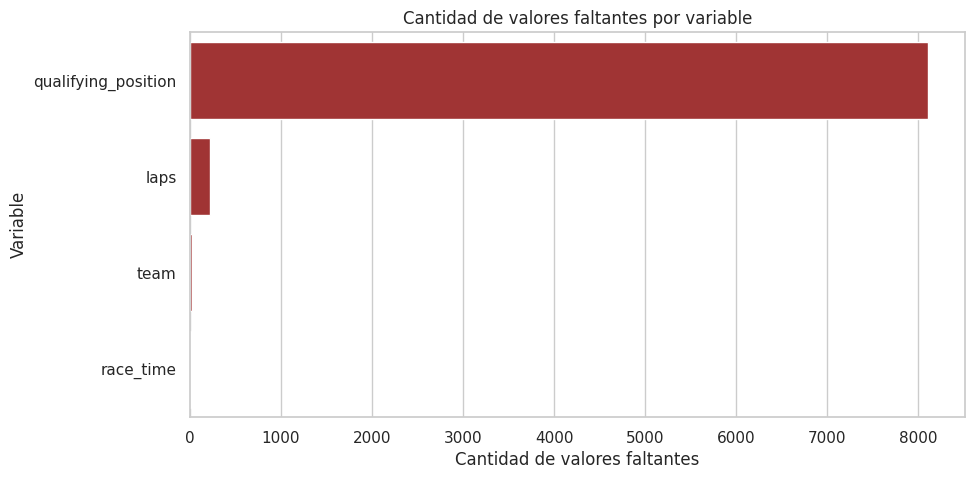

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_plot = missing[
    missing["cantidad_faltantes"] > 0
].reset_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_plot,
    x="cantidad_faltantes",
    y="index",
    color="firebrick"
)

plt.title("Cantidad de valores faltantes por variable")
plt.xlabel("Cantidad de valores faltantes")
plt.ylabel("Variable")

plt.show()


In [ ]:
duplicados = df.duplicated().sum()

print("Cantidad de filas completamente duplicadas:", duplicados)
print(
    "Porcentaje de filas duplicadas:",
    round(duplicados / len(df) * 100, 2),
    "%"
)


Cantidad de filas completamente duplicadas: 0
Porcentaje de filas duplicadas: 0.0 %


No se encontraron filas completamente duplicadas en el dataset integrado. Por lo tanto, no fue necesario eliminar registros antes de continuar con el análisis exploratorio.


In [ ]:
columnas_numericas = [
    "year",
    "final_position",
    "driver_number",
    "laps",
    "points",
    "qualifying_position"
]

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23155 entries, 0 to 23154
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 23155 non-null  int64  
 1   final_position       14438 non-null  float64
 2   driver_number        23155 non-null  int64  
 3   venue                23155 non-null  object 
 4   driver               23155 non-null  object 
 5   driver_tag           23155 non-null  object 
 6   team                 23129 non-null  object 
 7   laps                 22931 non-null  float64
 8   race_time            23147 non-null  object 
 9   points               23155 non-null  float64
 10  qualifying_position  15045 non-null  float64
dtypes: float64(4), int64(2), object(5)
memory usage: 1.9+ MB


## Resumen numérico de variables relevantes

A continuación se calculan medidas descriptivas como cantidad de observaciones, media, desvío estándar, mínimo, cuartiles y máximo. Estas medidas permiten observar el rango de las variables y detectar posibles valores atípicos o inconsistencias.


In [ ]:
resumen_numerico = df[
    [
        "year",
        "final_position",
        "qualifying_position",
        "laps",
        "points"
    ]
].describe().T

resumen_numerico


,count,mean,std,min,25%,50%,75%,max
year,23155.0,1989.708616,19.097436,1950.0,1976.0,1991.0,2006.0,2020.0
final_position,14438.0,8.091356,5.137336,1.0,4.0,7.0,11.0,33.0
qualifying_position,15045.0,11.428116,6.799164,1.0,6.0,11.0,17.0,27.0
laps,22931.0,49.029829,27.742497,0.0,29.0,53.0,67.0,200.0
points,23155.0,1.903010,4.096215,0.0,0.0,0.0,2.0,50.0


EDA
# Análisis Exploratorio de Datos
En esta sección se exploran las distribuciones, relaciones y tendencias históricas presentes en los resultados de Fórmula 1. El objetivo es identificar patrones relevantes sobre puntos, clasificación, pilotos, equipos y temporadas antes de construir el modelo predictivo.

## Distribución de puntos obtenidos

Este gráfico permite observar cómo se distribuyen los puntos obtenidos por los pilotos en cada carrera. Es útil para identificar si los puntos se concentran en ciertos valores y evaluar si la variable objetivo presenta una distribución equilibrada.


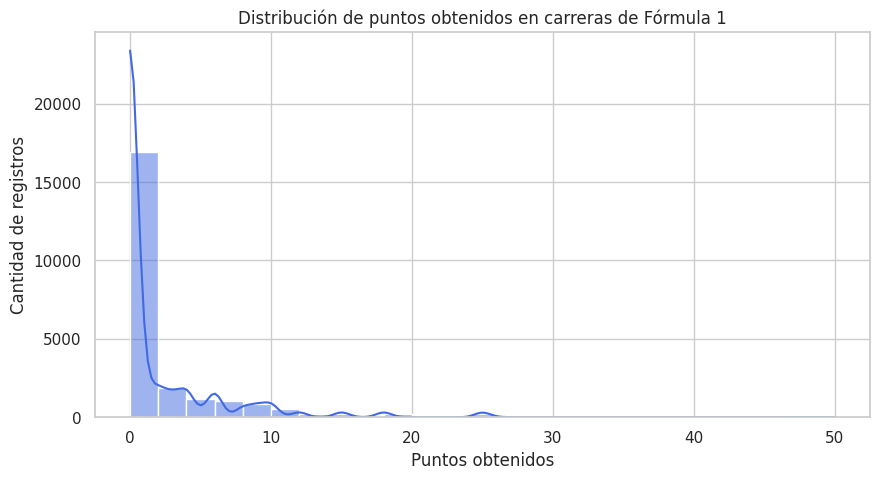

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="points",
    bins=25,
    kde=True,
    color="royalblue"
)

plt.title("Distribución de puntos obtenidos en carreras de Fórmula 1")
plt.xlabel("Puntos obtenidos")
plt.ylabel("Cantidad de registros")

plt.show()


### Interpretación

El gráfico muestra una relación inversa entre la posición de clasificación y los puntos promedio obtenidos en carrera. Las posiciones más bajas en la variable `qualifying_position` representan una mejor ubicación de salida, y se observa que los pilotos que clasifican en las primeras posiciones obtienen, en promedio, una mayor cantidad de puntos.

La posición de clasificación número 1 presenta el promedio de puntos más elevado. A medida que el piloto clasifica en posiciones más retrasadas, el promedio de puntos disminuye de forma sostenida y se aproxima a cero.

Este resultado respalda la hipótesis de que la posición de clasificación es una variable relevante para explicar y predecir los puntos obtenidos en una carrera. Por lo tanto, `qualifying_position` será incorporada como una de las variables predictoras principales en el modelo.


## Evolución de los puntos promedio por temporada

El sistema de puntuación de Fórmula 1 cambió a lo largo de la historia. Por este motivo, se analiza el promedio de puntos obtenidos por piloto y carrera en cada temporada, con el objetivo de observar tendencias y posibles cambios estructurales.



In [ ]:
points_by_year = (
    df.groupby("year", as_index=False)["points"]
      .mean()
)

display(points_by_year.head())


,year,points
0,1950,1.069620
1,1951,1.090909
2,1952,0.945813
3,1953,0.874494
4,1954,0.985388


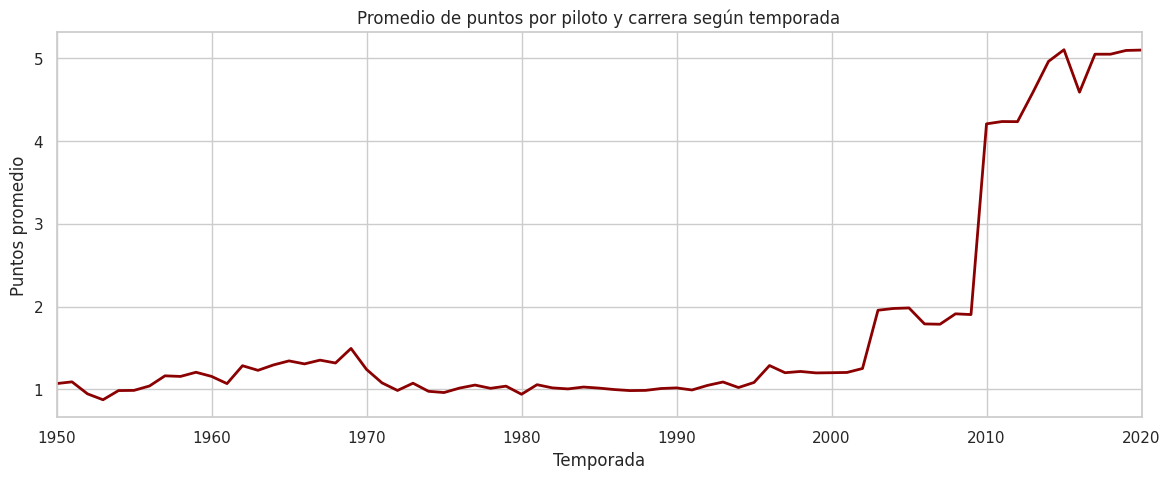

In [ ]:
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=points_by_year,
    x="year",
    y="points",
    color="darkred",
    linewidth=2
)

plt.title("Promedio de puntos por piloto y carrera según temporada")
plt.xlabel("Temporada")
plt.ylabel("Puntos promedio")
plt.xlim(1950, 2020)

plt.show()


In [ ]:
%whos


Variable                Type         Data/Info
----------------------------------------------
DATA_PATH               PosixPath    /root/.cache/kagglehub/da<...>19502019-data/versions/28
Path                    type         <class 'pathlib._local.Path'>
archivo                 PosixPath    /root/.cache/kagglehub/da<...>hampionship_1958-2020.csv
archivos_csv            list         n=17
columna                 str          qualifying_position
columnas_numericas      list         n=6
df                      DataFrame           year  final_positi<...>[23155 rows x 11 columns]
df_qualifying           DataFrame           year             v<...>n[15768 rows x 5 columns]
df_qualifying_new       DataFrame          Year      Venue Nam<...>\n[6089 rows x 5 columns]
df_qualifying_old       DataFrame          Year             Ve<...>\n[9949 rows x 5 columns]
df_races                DataFrame           Unnamed: 0  Year P<...>[23155 rows x 11 columns]
df_races_clean          DataFrame           year

### Interpretación

El promedio de puntos por piloto y carrera presenta variaciones importantes a lo largo de las temporadas analizadas. Durante gran parte del período histórico, entre 1950 y comienzos de los años 2000, el promedio se mantiene relativamente bajo y estable.

A partir de mediados de la década de 2000 se observa un crecimiento progresivo, seguido por un aumento muy marcado alrededor de la temporada 2010. Este cambio se vincula principalmente con modificaciones en el sistema de puntuación de Fórmula 1, que incrementaron los puntos asignados a las posiciones de llegada.

En los años posteriores, el promedio se estabiliza cerca de cinco puntos por piloto y carrera. Por lo tanto, el año es una variable relevante para el análisis y para el modelo predictivo, ya que permite considerar las diferencias históricas entre los sistemas de puntuación.


## Relación entre posición de clasificación y puntos obtenidos

La posición de clasificación representa la ubicación obtenida por un piloto antes de iniciar la carrera. Los valores más bajos indican una mejor posición de salida.

Se analiza su relación con los puntos obtenidos para evaluar si clasificar en posiciones delanteras se asocia con un mayor rendimiento final.


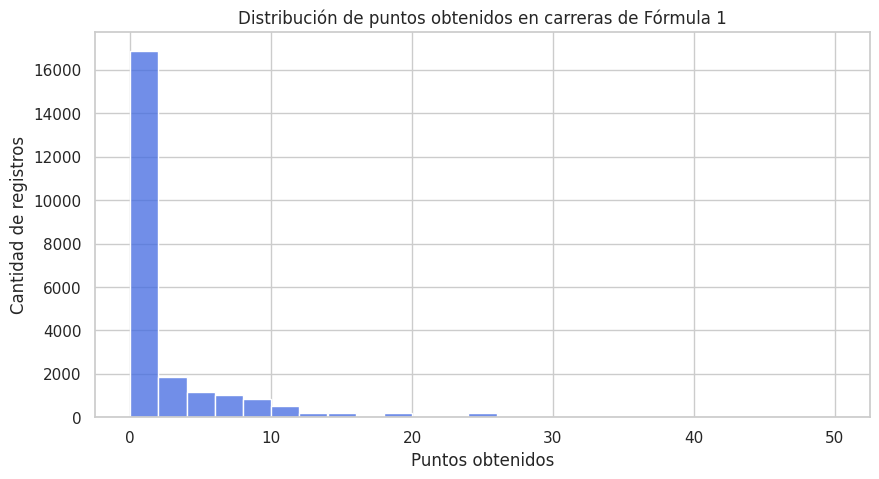

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="points",
    bins=25,
    color="royalblue"
)

plt.title("Distribución de puntos obtenidos en carreras de Fórmula 1")
plt.xlabel("Puntos obtenidos")
plt.ylabel("Cantidad de registros")

plt.show()


### Interpretación

La relación observada permite evaluar la hipótesis de que una mejor posición de clasificación se asocia con una mayor cantidad de puntos. Debido a que los valores más bajos de `qualifying_position` representan posiciones de salida más favorables, se espera que las primeras posiciones presenten promedios de puntos más altos.

A medida que empeora la posición de clasificación, el promedio de puntos tiende a disminuir. Este patrón sugiere que la clasificación puede ser una variable predictora relevante para estimar los puntos obtenidos en una carrera.



## Relación entre clasificación, puntos y período histórico

El sistema de puntuación de Fórmula 1 cambió a lo largo de las décadas. Para observar cómo varía la relación entre posición de clasificación y puntos obtenidos en distintos momentos históricos, se agruparán las carreras en períodos.

Este gráfico incorpora tres variables: posición de clasificación, puntos obtenidos y período histórico.


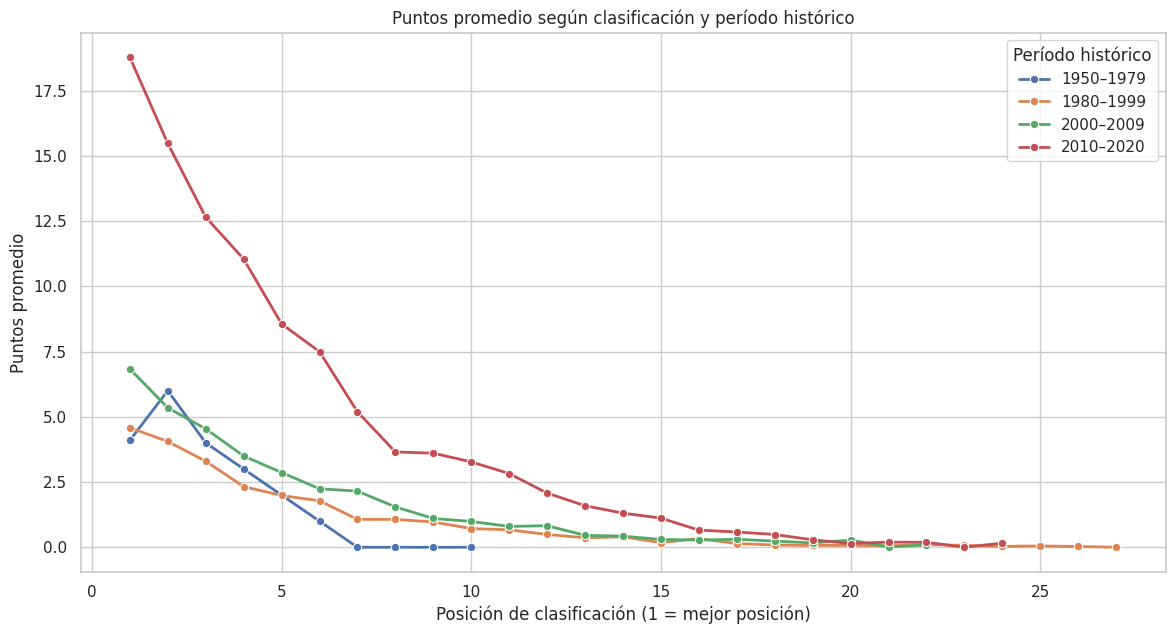

In [ ]:
df_multivar = df.dropna(
    subset=["qualifying_position", "points", "year"]
).copy()

df_multivar["period"] = pd.cut(
    df_multivar["year"],
    bins=[1949, 1979, 1999, 2009, 2020],
    labels=[
        "1950–1979",
        "1980–1999",
        "2000–2009",
        "2010–2020"
    ]
)

points_by_period_qualifying = (
    df_multivar
    .groupby(
        ["period", "qualifying_position"],
        observed=True,
        as_index=False
    )["points"]
    .mean()
)

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=points_by_period_qualifying,
    x="qualifying_position",
    y="points",
    hue="period",
    marker="o",
    linewidth=2
)

plt.title(
    "Puntos promedio según clasificación y período histórico"
)
plt.xlabel("Posición de clasificación (1 = mejor posición)")
plt.ylabel("Puntos promedio")
plt.legend(title="Período histórico")

plt.show()


### Interpretación

En todos los períodos históricos se observa una relación inversa entre la posición de clasificación y los puntos promedio obtenidos. Los pilotos que clasifican en posiciones delanteras tienden a obtener una mayor cantidad de puntos, mientras que los promedios disminuyen a medida que la posición de salida empeora.

Las diferencias en la altura de las líneas entre períodos se relacionan principalmente con los cambios históricos en el sistema de puntuación de Fórmula 1. En particular, el período 2010–2020 presenta promedios de puntos más elevados, debido a que se ampliaron los puntos otorgados a las posiciones de llegada.

Por lo tanto, aunque la relación entre clasificación y puntos se mantiene a lo largo del tiempo, su magnitud varía según el período histórico analizado.


## Dispersión entre posición de clasificación y puntos

El siguiente gráfico representa cada participación de un piloto en una carrera. Permite observar la dispersión de los puntos obtenidos según la posición de clasificación, además de identificar la concentración de resultados en cero puntos.


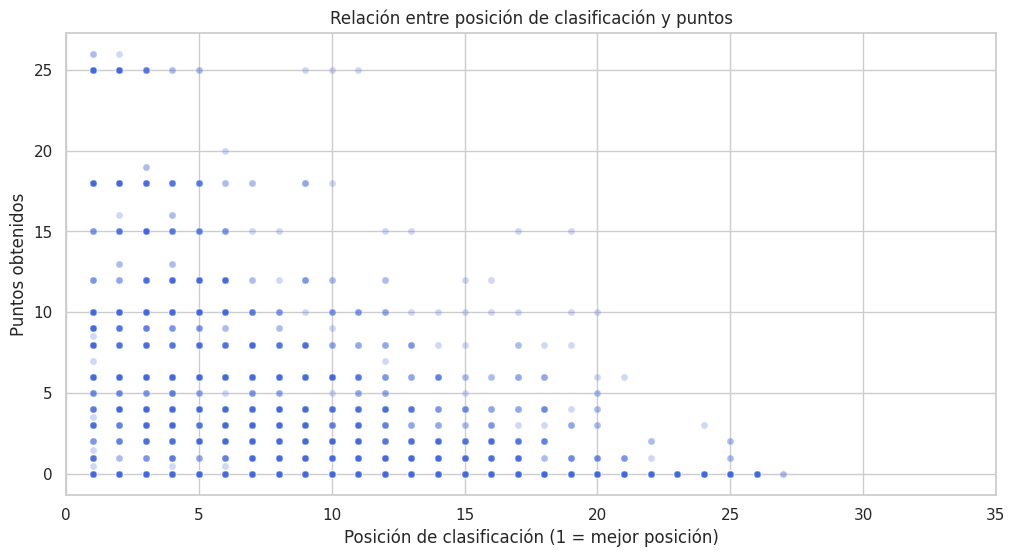

In [ ]:
df_scatter = df.dropna(
    subset=["qualifying_position", "points"]
).copy()

df_scatter_sample = df_scatter.sample(
    n=min(5000, len(df_scatter)),
    random_state=42
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_scatter_sample,
    x="qualifying_position",
    y="points",
    alpha=0.25,
    color="royalblue",
    s=25
)

plt.title("Relación entre posición de clasificación y puntos")
plt.xlabel("Posición de clasificación (1 = mejor posición)")
plt.ylabel("Puntos obtenidos")
plt.xlim(0, 35)

plt.show()


### Interpretación

El scatterplot muestra una alta concentración de observaciones con cero puntos, especialmente entre las posiciones de clasificación más retrasadas. Sin embargo, los valores de puntos más altos se concentran principalmente en las primeras posiciones de clasificación.

También se observa dispersión: clasificar bien no garantiza obtener puntos, ya que pueden ocurrir abandonos, errores, sanciones o cambios durante la carrera. Aun así, el patrón general indica que una mejor posición de salida se asocia con una mayor probabilidad de obtener puntos.


## Distribución de puntos según grupos de clasificación

Para resumir la relación entre posición de salida y puntos, se agrupan las posiciones de clasificación en categorías. El boxplot permite comparar la mediana, la dispersión y los valores extremos de puntos entre pilotos que clasificaron en distintas zonas de la grilla.


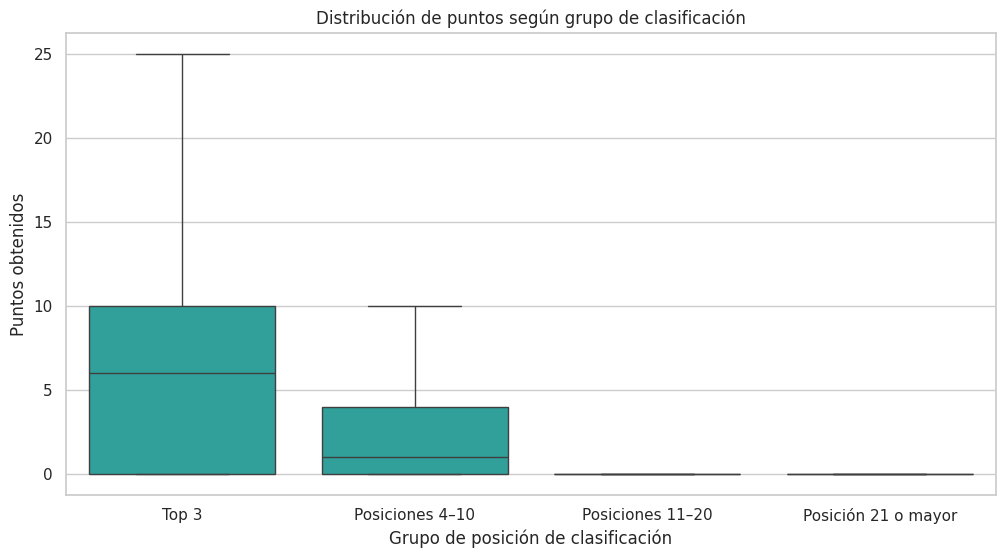

In [ ]:
df_boxplot = df.dropna(
    subset=["qualifying_position", "points"]
).copy()

df_boxplot["qualifying_group"] = pd.cut(
    df_boxplot["qualifying_position"],
    bins=[0, 3, 10, 20, 50],
    labels=[
        "Top 3",
        "Posiciones 4–10",
        "Posiciones 11–20",
        "Posición 21 o mayor"
    ]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_boxplot,
    x="qualifying_group",
    y="points",
    color="lightseagreen",
    showfliers=False
)

plt.title("Distribución de puntos según grupo de clasificación")
plt.xlabel("Grupo de posición de clasificación")
plt.ylabel("Puntos obtenidos")

plt.show()


### Interpretación

El boxplot permite comparar la distribución de puntos según la zona de clasificación. Se espera que el grupo de pilotos que clasificó entre las primeras tres posiciones presente una mediana de puntos más alta y una mayor presencia de valores elevados.

En cambio, los grupos que clasificaron en posiciones más retrasadas tienden a concentrarse en valores bajos o iguales a cero. Esto refuerza la evidencia de que la posición de clasificación es una variable importante para anticipar el rendimiento final medido mediante los puntos obtenidos.


## Equipos con mayor promedio de puntos

Se analiza el promedio de puntos obtenidos por cada equipo para identificar las escuderías con mejor desempeño general dentro del dataset. Para evitar conclusiones basadas en equipos con muy pocas participaciones, se consideran únicamente aquellos equipos con una cantidad mínima de registros.


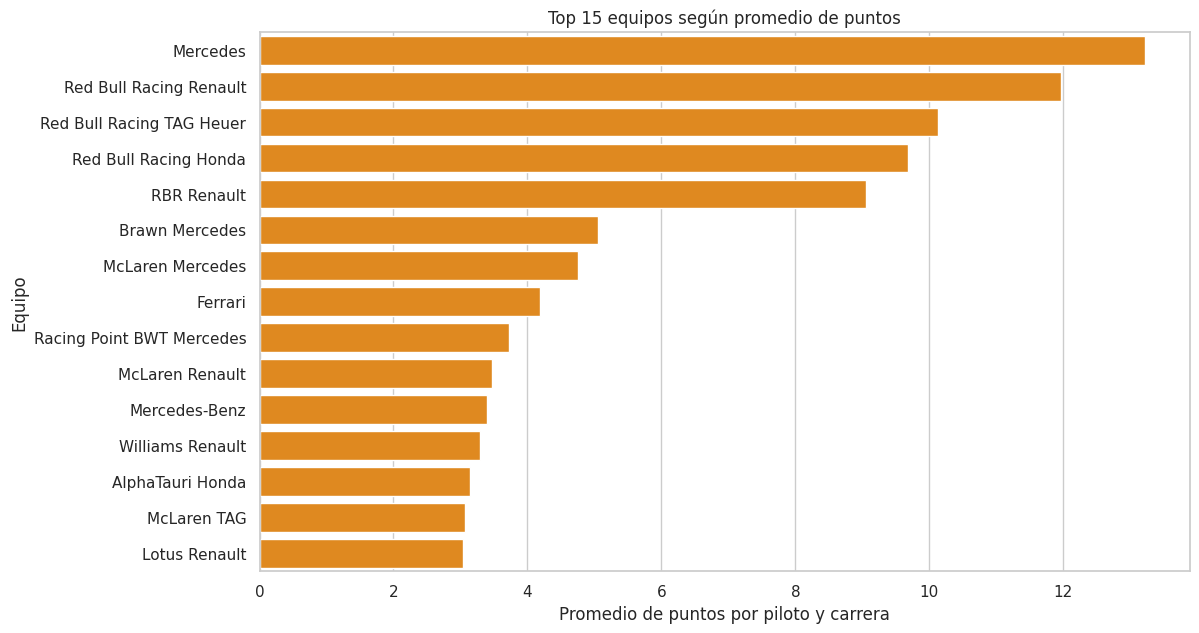

In [ ]:
team_summary = (
    df.dropna(subset=["team", "points"])
    .groupby("team", as_index=False)
    .agg(
        promedio_puntos=("points", "mean"),
        participaciones=("points", "count")
    )
)

team_top = (
    team_summary[
        team_summary["participaciones"] >= 30
    ]
    .sort_values("promedio_puntos", ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=team_top,
    x="promedio_puntos",
    y="team",
    color="darkorange"
)

plt.title("Top 15 equipos según promedio de puntos")
plt.xlabel("Promedio de puntos por piloto y carrera")
plt.ylabel("Equipo")

plt.show()


### Interpretación

El gráfico muestra los equipos con mayor promedio de puntos entre aquellos que registran al menos 30 participaciones. Los primeros puestos corresponden a escuderías que tuvieron un desempeño competitivo destacado durante los años incluidos en el dataset.

Sin embargo, la comparación debe interpretarse con cautela, ya que los equipos participaron en diferentes períodos históricos y estuvieron sujetos a distintos sistemas de puntuación. Por esta razón, el promedio histórico de puntos refleja tanto el rendimiento deportivo como el contexto temporal en el que compitió cada equipo.


# Modelo Predictivo

El objetivo del modelo es predecir los puntos obtenidos por un piloto en una carrera de Fórmula 1. Se utilizarán únicamente variables conocidas antes de que comience la carrera, evitando incorporar información disponible después del resultado final.


In [ ]:
print(df.columns.tolist())


['year', 'final_position', 'driver_number', 'venue', 'driver', 'driver_tag', 'team', 'laps', 'race_time', 'points', 'qualifying_position']


## Construcción del dataset para modelado

Se construye un dataset con variables disponibles antes del inicio de la carrera. Se incluyen el año, la posición de clasificación, el equipo, el piloto y el circuito o sede de la carrera.

Se excluyen variables que contienen información posterior a la carrera, como la posición final, las vueltas completadas y el tiempo de carrera, para evitar data leakage.


In [ ]:
model_columns = [
    "year",
    "qualifying_position",
    "team",
    "driver",
    "venue",
    "points"
]

df_model = df[model_columns].copy()

print("Dimensiones del dataset para modelado:", df_model.shape)

display(df_model.head())

print("\nValores faltantes por columna:")
print(df_model.isnull().sum())


Dimensiones del dataset para modelado: (23155, 6)


,year,qualifying_position,team,driver,venue,points
0,1950,1.0,Alfa Romeo,Nino Farina,great-britain,9.0
1,1950,NaN,Alfa Romeo,Luigi Fagioli,great-britain,6.0
2,1950,NaN,Alfa Romeo,Reg Parnell,great-britain,4.0
3,1950,NaN,Talbot-Lago,Yves Giraud Cabantous,great-britain,3.0
4,1950,NaN,Talbot-Lago,Louis Rosier,great-britain,2.0



Valores faltantes por columna:
year                      0
qualifying_position    8110
team                     26
driver                    0
venue                     0
points                    0
dtype: int64


## Tratamiento inicial de valores faltantes

Los registros sin información de puntos no pueden utilizarse para entrenar un modelo supervisado, ya que los puntos constituyen la variable objetivo.

Los valores faltantes en las variables predictoras se conservarán inicialmente. Posteriormente, serán tratados mediante un pipeline de preprocesamiento para evitar eliminar innecesariamente observaciones históricas.


In [ ]:
df_model = df_model.dropna(subset=["points"]).copy()

print("Dimensiones luego de eliminar puntos faltantes:", df_model.shape)

print("\nValores faltantes restantes:")
print(df_model.isnull().sum())

print("\nEstadísticas de qualifying_position:")
display(df_model["qualifying_position"].describe())


Dimensiones luego de eliminar puntos faltantes: (23155, 6)

Valores faltantes restantes:
year                      0
qualifying_position    8110
team                     26
driver                    0
venue                     0
points                    0
dtype: int64

Estadísticas de qualifying_position:


,qualifying_position
count,15045.000000
mean,11.428116
std,6.799164
min,1.000000
25%,6.000000
50%,11.000000
75%,17.000000
max,27.000000


## Variables predictoras y variable objetivo

La variable objetivo será `points`, que representa los puntos obtenidos por un piloto en una carrera.

Las variables predictoras seleccionadas son el año, la posición de clasificación, el equipo, el piloto y la sede de la carrera. Todas ellas representan información disponible antes de que se conozca el resultado final.


In [ ]:
X = df_model.drop(columns="points")
y = df_model["points"]

print("Variables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)


Variables predictoras:
['year', 'qualifying_position', 'team', 'driver', 'venue']

Variable objetivo:
points


## División temporal de entrenamiento y prueba

Para simular un escenario realista de predicción, se realiza una división temporal. El modelo se entrena con temporadas anteriores a 2017 y se evalúa con las temporadas comprendidas entre 2017 y 2020.

Este enfoque evita que el modelo utilice información futura durante el entrenamiento.


In [ ]:
train_mask = X["year"] < 2017
test_mask = X["year"] >= 2017

X_train = X[train_mask].copy()
X_test = X[test_mask].copy()

y_train = y[train_mask].copy()
y_test = y[test_mask].copy()

print("Tamaño del conjunto de entrenamiento:", X_train.shape)
print("Tamaño del conjunto de prueba:", X_test.shape)

print("\nPeríodo de entrenamiento:")
print(X_train["year"].min(), "-", X_train["year"].max())

print("\nPeríodo de prueba:")
print(X_test["year"].min(), "-", X_test["year"].max())

print("\nPuntos promedio en entrenamiento:", round(y_train.mean(), 2))
print("Puntos promedio en prueba:", round(y_test.mean(), 2))


Tamaño del conjunto de entrenamiento: (21575, 5)
Tamaño del conjunto de prueba: (1580, 5)

Período de entrenamiento:
1950 - 2016

Período de prueba:
2017 - 2020

Puntos promedio en entrenamiento: 1.67
Puntos promedio en prueba: 5.07


## Preprocesamiento de variables

Las variables numéricas y categóricas requieren tratamientos diferentes. La posición de clasificación se imputará con la mediana cuando presente valores faltantes.

Las variables categóricas —equipo, piloto y sede— se transformarán mediante codificación one-hot. Este proceso crea variables binarias que permiten al modelo utilizar información categórica.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


In [ ]:
numeric_features = [
    "year",
    "qualifying_position"
]

categorical_features = [
    "team",
    "driver",
    "venue"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


In [ ]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)

dummy_rmse = np.sqrt(
    mean_squared_error(y_test, dummy_predictions)
)

dummy_r2 = r2_score(y_test, dummy_predictions)

print("Resultados del modelo base (Dummy Regressor)")
print("MAE:", round(dummy_mae, 3))
print("RMSE:", round(dummy_rmse, 3))
print("R²:", round(dummy_r2, 3))


Resultados del modelo base (Dummy Regressor)
MAE: 5.14
RMSE: 7.972
R²: -0.223


## Modelo Random Forest Regressor

Se entrena un modelo Random Forest Regressor para predecir los puntos obtenidos. Este algoritmo combina múltiples árboles de decisión y calcula un promedio de sus predicciones, lo que permite modelar relaciones no lineales entre las variables de entrada y los puntos obtenidos.


In [ ]:
from sklearn.ensemble import RandomForestRegressor


In [ ]:
random_forest = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", random_forest)
])

rf_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['year',
                                                   'qualifying_position']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['team', 'driver',
                                                   'venue'])])),
                ('model',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=3,
                                       n_estimators=200, n_jobs=-1,
                                       random_state=42))])

## Evaluación del modelo

El modelo se evalúa utilizando las temporadas 2017 a 2020, que no fueron utilizadas durante el entrenamiento.

Se emplean tres métricas:

- MAE: error absoluto promedio en puntos.
- RMSE: penaliza con mayor intensidad los errores grandes.
- R²: proporción de la variabilidad de los puntos explicada por el modelo.


In [ ]:
import numpy as np

rf_predictions = rf_pipeline.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Resultados del Random Forest")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R²:", round(rf_r2, 3))


Resultados del Random Forest
MAE: 3.402
RMSE: 4.931
R²: 0.532


In [ ]:
results = pd.DataFrame({
    "Modelo": [
        "Dummy Regressor",
        "Random Forest"
    ],
    "MAE": [
        dummy_mae,
        rf_mae
    ],
    "RMSE": [
        dummy_rmse,
        rf_rmse
    ],
    "R²": [
        dummy_r2,
        rf_r2
    ]
})

display(results.round(3))


,Modelo,MAE,RMSE,R²
0,Dummy Regressor,5.140,7.972,-0.223
1,Random Forest,3.402,4.931,0.532


## Comparación de modelos

El modelo Random Forest obtuvo un mejor desempeño que el Dummy Regressor en todas las métricas evaluadas.

El Dummy Regressor presenta un MAE de 5.140 puntos y un RMSE de 7.972 puntos. Además, su valor de R² es negativo (-0.223), lo que indica que predecir simplemente el promedio histórico de puntos no explica adecuadamente la variabilidad observada en el conjunto de prueba.

En cambio, el Random Forest logró reducir el MAE a 3.402 puntos y el RMSE a 4.931 puntos. Esto significa que, en promedio, sus predicciones se alejan aproximadamente 3.4 puntos del valor real.

El valor de R² del Random Forest es 0.532. Por lo tanto, el modelo explica aproximadamente el 53.2% de la variabilidad de los puntos obtenidos en las temporadas de prueba, comprendidas entre 2017 y 2020.

En conclusión, las variables disponibles antes de la carrera —año, posición de clasificación, equipo, piloto y sede— permiten predecir los puntos con un desempeño considerablemente superior al modelo base.


## Puntos reales versus puntos predichos

Cada punto representa una observación del conjunto de prueba. La línea roja representa una predicción perfecta: los casos ubicados sobre esta línea tendrían exactamente la misma cantidad de puntos reales y predichos.

Los puntos cercanos a la línea indican predicciones precisas, mientras que los puntos alejados reflejan errores de predicción. Debido a que en Fórmula 1 pueden ocurrir abandonos, accidentes, sanciones o problemas mecánicos durante la carrera, no es esperable que todas las observaciones se ubiquen exactamente sobre la línea.

A pesar de esta variabilidad, el desempeño del Random Forest muestra que la posición de clasificación, el equipo, el piloto, el año y la sede aportan información útil para estimar los puntos finales.


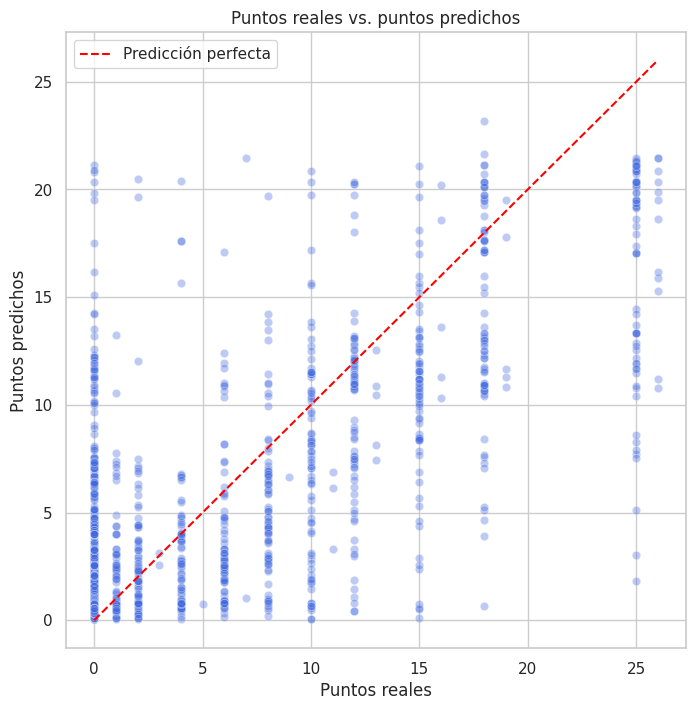

In [ ]:
plt.figure(figsize=(8, 8))

sns.scatterplot(
    x=y_test,
    y=rf_predictions,
    alpha=0.35,
    color="royalblue"
)

max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.title("Puntos reales vs. puntos predichos")
plt.xlabel("Puntos reales")
plt.ylabel("Puntos predichos")
plt.legend()

plt.show()


### Interpretación

El gráfico compara los puntos reales con los puntos estimados por el modelo Random Forest. La línea roja punteada representa una predicción perfecta, es decir, los casos en los que los puntos predichos coinciden exactamente con los puntos reales.

En general, una parte importante de las observaciones se concentra cerca de la línea diagonal y alrededor de cero puntos, lo que indica que el modelo logra identificar varios casos de bajo puntaje o ausencia de puntos.

Sin embargo, también se observa dispersión respecto de la línea de referencia, particularmente en los valores de puntaje más elevados. Esto significa que el modelo no siempre estima con precisión los puntos finales, probablemente porque existen factores que ocurren durante la carrera —como abandonos, accidentes, sanciones o decisiones estratégicas— que no se incluyeron como variables predictoras.

Aun con estas limitaciones, el modelo presenta un desempeño superior al modelo base y explica aproximadamente el 53.2% de la variabilidad de los puntos en el conjunto de prueba.


 Evaluación de modelos en entrenamiento y prueba


In [ ]:
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)


DummyRegressor()

In [ ]:
dummy_model.predict(X_train[:3])


array([1.67087833, 1.67087833, 1.67087833])

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def calcular_metricas(modelo, X, y_real):
    """
    Calcula métricas de regresión para un modelo
    y un conjunto de datos determinado.
    """

    predicciones = modelo.predict(X)

    mae = mean_absolute_error(y_real, predicciones)

    rmse = np.sqrt(
        mean_squared_error(y_real, predicciones)
    )

    r2 = r2_score(y_real, predicciones)

    return mae, rmse, r2


# Métricas del Dummy Regressor en train y test
dummy_mae_train, dummy_rmse_train, dummy_r2_train = calcular_metricas(
    dummy_model,
    X_train,
    y_train
)

dummy_mae_test, dummy_rmse_test, dummy_r2_test = calcular_metricas(
    dummy_model,
    X_test,
    y_test
)


# Métricas del Random Forest en train y test
rf_mae_train, rf_rmse_train, rf_r2_train = calcular_metricas(
    rf_pipeline,
    X_train,
    y_train
)

rf_mae_test, rf_rmse_test, rf_r2_test = calcular_metricas(
    rf_pipeline,
    X_test,
    y_test
)


# Tabla comparativa final
evaluacion_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Regressor",
        "Dummy Regressor",
        "Random Forest",
        "Random Forest"
    ],
    "Conjunto": [
        "Train",
        "Test",
        "Train",
        "Test"
    ],
    "MAE": [
        dummy_mae_train,
        dummy_mae_test,
        rf_mae_train,
        rf_mae_test
    ],
    "RMSE": [
        dummy_rmse_train,
        dummy_rmse_test,
        rf_rmse_train,
        rf_rmse_test
    ],
    "R²": [
        dummy_r2_train,
        dummy_r2_test,
        rf_r2_train,
        rf_r2_test
    ]
})

display(evaluacion_modelos.round(3))


,Modelo,Conjunto,MAE,RMSE,R²
0,Dummy Regressor,Train,2.396,3.662,0.000
1,Dummy Regressor,Test,5.140,7.972,-0.223
2,Random Forest,Train,1.345,2.191,0.642
3,Random Forest,Test,3.402,4.931,0.532


## Evaluación de modelos en train y test

Se evaluaron los modelos tanto sobre el conjunto de entrenamiento como sobre el conjunto de prueba, con el objetivo de analizar su desempeño y verificar su capacidad de generalización.

El Dummy Regressor se utilizó como modelo base. En entrenamiento obtuvo un MAE de 2.396 y un R² de 0.000, ya que predice el promedio de puntos del conjunto de entrenamiento. En test, su desempeño empeora: presenta un MAE de 5.140, un RMSE de 7.972 y un R² de -0.223. Esto indica que predecir únicamente el promedio histórico no resulta una estrategia adecuada para estimar los puntos en temporadas futuras.

El modelo Random Forest obtuvo un desempeño superior al modelo base en ambos conjuntos. En train alcanzó un MAE de 1.345, un RMSE de 2.191 y un R² de 0.642. En test logró un MAE de 3.402, un RMSE de 4.931 y un R² de 0.532.

Es esperable que el desempeño en entrenamiento sea mejor que en prueba, dado que el modelo fue ajustado utilizando los datos de train. Sin embargo, la diferencia entre los resultados de train y test no es extrema: el modelo conserva un R² superior a 0.5 en datos no vistos y reduce el error absoluto medio respecto del Dummy Regressor de 5.140 a 3.402 puntos.

Por lo tanto, se concluye que el Random Forest presenta una capacidad de generalización razonable para estimar los puntos obtenidos por un piloto en carreras de temporadas posteriores. Aun así, existe una diferencia entre train y test que puede indicar un nivel moderado de sobreajuste, por lo que podrían incorporarse variables adicionales o aplicarse ajuste de hiperparámetros en trabajos futuros.


# Conclusiones finales

El análisis exploratorio permitió identificar patrones relevantes en los resultados de Fórmula 1. La posición de clasificación presentó una relación clara con los puntos obtenidos: los pilotos que parten desde posiciones más adelantadas tienden a tener una mayor probabilidad de sumar puntos.

También se observaron diferencias entre pilotos, equipos y temporadas, lo que evidencia que el rendimiento depende tanto de la posición de salida como de factores asociados a la escudería, al piloto y al contexto de cada carrera.

Posteriormente, se entrenó un modelo Random Forest para predecir los puntos obtenidos utilizando variables disponibles antes de la carrera: año, posición de clasificación, equipo, piloto y sede.

El modelo obtuvo un MAE de 3.402 puntos, un RMSE de 4.931 puntos y un valor de R² de 0.532 en las temporadas de prueba entre 2017 y 2020. Estos resultados fueron superiores a los obtenidos por el Dummy Regressor, que simplemente predice el promedio histórico de puntos.

Aunque el modelo explica aproximadamente el 53.2% de la variabilidad de los puntos, existen factores no incluidos que pueden afectar el resultado final, como accidentes, abandonos, condiciones climáticas, decisiones estratégicas, sanciones y fallas mecánicas.

En conclusión, el modelo demuestra que la información disponible antes de la largada permite realizar predicciones útiles sobre los puntos finales, aunque no puede capturar por completo la incertidumbre propia de una carrera de Fórmula 1.


## Posibles mejoras futuras

El modelo podría mejorarse incorporando variables adicionales disponibles antes de la carrera, como condiciones climáticas previstas, rendimiento reciente del piloto y del equipo, resultados de carreras anteriores, posición histórica en el circuito y datos de práctica libre.

También sería posible comparar el desempeño del Random Forest con otros modelos de regresión, como Gradient Boosting, XGBoost o regresión lineal regularizada.

Finalmente, se podría aplicar una validación cruzada temporal para evaluar el comportamiento del modelo en distintos períodos históricos de Fórmula 1.
